<a href="https://colab.research.google.com/github/SebastianoColombini/NN_DL_project/blob/main/v1.1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **IMPORT AND NETWORK VERSION**

In [1]:
# Import section
from google.colab import drive
import os
import json
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import shutil
import os
import json
import shutil
import zipfile
from google.colab import drive
from torch.nn.modules import conv
import time
import matplotlib.pyplot as plt
import random

In [2]:

version = {
    "version_name": "1.1",
    "lr": 0.001,
    "epochs":150,
    "batch_size":16,
    "optimizer": "Adam",
    "patience": 15,
    "min_delta": 1e-4

}

## **SALICON DATASET LOADING**

In [3]:
# Drive synchronization (where all versions and snapshots are saved)
drive.mount('/content/drive')

DRIVE_DIR = "/content/drive/MyDrive/NN_DL_Proj"
VERSION_DIR = os.path.join(DRIVE_DIR, version["version_name"])
SNAPSHOTS_DIR = os.path.join(VERSION_DIR, "snapshots")
DB_DRIVE_DIR = os.path.join(DRIVE_DIR, 'DB')

os.makedirs(VERSION_DIR, exist_ok=True)
os.makedirs(SNAPSHOTS_DIR, exist_ok=True)

LOCAL_DB_DIR = "/content/extracted_db"

# LOCAR_DB_DIR is cleaned every run
if os.path.exists(LOCAL_DB_DIR):
    print(f"Cleaning existing directory: {LOCAL_DB_DIR}")
    shutil.rmtree(LOCAL_DB_DIR)
os.makedirs(LOCAL_DB_DIR, exist_ok=True)

# Extract all datasets
def extract_dataset(zip_path, dest_dir):
    if os.path.exists(zip_path):
        print(f"Estrazione di {os.path.basename(zip_path)} in corso...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(dest_dir)
        print(f"Estrazione di {os.path.basename(zip_path)} completata.")
    else:
        print(f"ATTENZIONE: File {zip_path} non trovato.")

for zip_file in [f for f in os.listdir(DB_DRIVE_DIR) if f.endswith('.zip')]:
    extract_dataset(os.path.join(DB_DRIVE_DIR, zip_file), LOCAL_DB_DIR)

TRAIN_IMAGES_DIR = os.path.join(LOCAL_DB_DIR, 'images', 'train')
TRAIN_SALIENCY_MAPS_DIR = os.path.join(LOCAL_DB_DIR, 'maps', 'train')
VAL_IMAGES_DIR = os.path.join(LOCAL_DB_DIR, 'images', 'val')
VAL_SALIENCY_MAPS_DIR = os.path.join(LOCAL_DB_DIR, 'maps', 'val')

#

version_file_path = os.path.join(VERSION_DIR, "version.json") #kind of useless
with open(version_file_path, 'w') as f:
    json.dump(version, f, indent=4)

# Directories:
print(f"- TRAIN_IMAGES_DIR: {TRAIN_IMAGES_DIR}")
print(f"- TRAIN_SALIENCY_MAPS_DIR: {TRAIN_SALIENCY_MAPS_DIR}")
print(f"- VAL_IMAGES_DIR: {VAL_IMAGES_DIR}")
print(f"- VAL_SALIENCY_MAPS_DIR: {VAL_SALIENCY_MAPS_DIR}")

Mounted at /content/drive
Estrazione di images.zip in corso...
Estrazione di images.zip completata.
Estrazione di maps.zip in corso...
Estrazione di maps.zip completata.
- TRAIN_IMAGES_DIR: /content/extracted_db/images/train
- TRAIN_SALIENCY_MAPS_DIR: /content/extracted_db/maps/train
- VAL_IMAGES_DIR: /content/extracted_db/images/val
- VAL_SALIENCY_MAPS_DIR: /content/extracted_db/maps/val


In [4]:
class SALICONDataset(Dataset):
    def __init__(self, image_root_dir, saliency_map_root_dir, transform=None):
        self.image_root_dir = image_root_dir
        self.saliency_map_root_dir = saliency_map_root_dir
        self.transform = transform

        VALID_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')

        # Delete non images from the dataset (.DS_Store, Thumbs.db, Jupyter checkpoints, etc.)
        image_files = sorted(f for f in os.listdir(image_root_dir) if f.lower().endswith(VALID_EXTS))
        map_files = sorted(f for f in os.listdir(saliency_map_root_dir) if f.lower().endswith(VALID_EXTS))

        assert len(image_files) == len(map_files), \
            f"Mismatch: {len(image_files)} images vs {len(map_files)} maps"

        # Verify that images match 1:1 with the related maps (same name)
        for img_f, map_f in zip(image_files, map_files):
            img_stem = os.path.splitext(img_f)[0]
            map_stem = os.path.splitext(map_f)[0]
            assert img_stem == map_stem, \
                f"Filename mismatch: image '{img_f}' vs map '{map_f}'"

        self.image_filenames = image_files
        self.saliency_map_filenames = map_files

    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, idx):
        img_name = os.path.join(self.image_root_dir, self.image_filenames[idx])
        saliency_name = os.path.join(self.saliency_map_root_dir, self.saliency_map_filenames[idx])

        image = Image.open(img_name).convert('RGB')
        saliency_map = Image.open(saliency_name).convert('L')

        if self.transform:
            image = self.transform(image)
            saliency_map = self.transform(saliency_map)

        return image, saliency_map

transforms_train = transforms.Compose([
    transforms.Resize((240,320)), # size used for training
    transforms.ToTensor(),
])

# DATALOADER initialization
train_salicon_dataset = SALICONDataset(
    image_root_dir=TRAIN_IMAGES_DIR,
    saliency_map_root_dir=TRAIN_SALIENCY_MAPS_DIR,
    transform=transforms_train
)
val_salicon_dataset = SALICONDataset(
    image_root_dir=VAL_IMAGES_DIR,
    saliency_map_root_dir=VAL_SALIENCY_MAPS_DIR,
    transform=transforms_train
)

print(f"Number of samples in SALICON training dataset: {len(train_salicon_dataset)}")
print(f"Number of samples in SALICON validation dataset: {len(val_salicon_dataset)}")

Number of samples in SALICON training dataset: 10000
Number of samples in SALICON validation dataset: 5000


## **MIT1003 TEST SET LOADING**

Held-out test set used only for final evaluation (never seen during training). Images are paired with their continuous fixation ("saliency") maps, e.g. `foo.jpeg` <-> `foo_fixMap.jpg`. The raw archives also contain binary fixation-point maps (`*_fixPts.jpg`) and Subversion/`__MACOSX` housekeeping files, which are ignored here.

In [5]:
MIT_DRIVE_DIR = os.path.join(DB_DRIVE_DIR, 'MIT_DATASET')
LOCAL_MIT_DIR = "/content/extracted_mit"

# LOCAL_MIT_DIR is cleaned every run
if os.path.exists(LOCAL_MIT_DIR):
    print(f"Cleaning existing directory: {LOCAL_MIT_DIR}")
    shutil.rmtree(LOCAL_MIT_DIR)
os.makedirs(LOCAL_MIT_DIR, exist_ok=True)

for zip_file in ['ALLSTIMULI.zip', 'ALLFIXATIONMAPS.zip']:
    extract_dataset(os.path.join(MIT_DRIVE_DIR, zip_file), LOCAL_MIT_DIR)

TEST_IMAGES_DIR = os.path.join(LOCAL_MIT_DIR, 'ALLSTIMULI')
TEST_SALIENCY_MAPS_DIR = os.path.join(LOCAL_MIT_DIR, 'ALLFIXATIONMAPS')

print(f"- TEST_IMAGES_DIR: {TEST_IMAGES_DIR}")
print(f"- TEST_SALIENCY_MAPS_DIR: {TEST_SALIENCY_MAPS_DIR}")

Estrazione di ALLSTIMULI.zip in corso...
Estrazione di ALLSTIMULI.zip completata.
Estrazione di ALLFIXATIONMAPS.zip in corso...
Estrazione di ALLFIXATIONMAPS.zip completata.
- TEST_IMAGES_DIR: /content/extracted_mit/ALLSTIMULI
- TEST_SALIENCY_MAPS_DIR: /content/extracted_mit/ALLFIXATIONMAPS


In [6]:
class MITTestDataset(Dataset):
    """MIT1003 test set: pairs each stimulus with its continuous fixation map (name.jpeg <-> name_fixMap.jpg)."""
    def __init__(self, image_root_dir, saliency_map_root_dir, transform=None):
        self.image_root_dir = image_root_dir
        self.saliency_map_root_dir = saliency_map_root_dir
        self.transform = transform

        VALID_IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')
        MAP_SUFFIX = '_fixMap.jpg'

        image_files = sorted(f for f in os.listdir(image_root_dir) if f.lower().endswith(VALID_IMG_EXTS))
        map_files_by_stem = {
            f[:-len(MAP_SUFFIX)]: f
            for f in os.listdir(saliency_map_root_dir) if f.endswith(MAP_SUFFIX)
        }

        self.samples = []
        for img_f in image_files:
            stem = os.path.splitext(img_f)[0]
            assert stem in map_files_by_stem, f"Missing fixation map for image '{img_f}'"
            self.samples.append((img_f, map_files_by_stem[stem]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_f, map_f = self.samples[idx]

        image = Image.open(os.path.join(self.image_root_dir, img_f)).convert('RGB')
        saliency_map = Image.open(os.path.join(self.saliency_map_root_dir, map_f)).convert('L')

        if self.transform:
            image = self.transform(image)
            saliency_map = self.transform(saliency_map)

        return image, saliency_map

# DATALOADER initialization
test_dataset = MITTestDataset(
    image_root_dir=TEST_IMAGES_DIR,
    saliency_map_root_dir=TEST_SALIENCY_MAPS_DIR,
    transform=transforms_train
)

print(f"Number of samples in MIT1003 test dataset: {len(test_dataset)}")

Number of samples in MIT1003 test dataset: 1003


## **NETWORK ARCHITECTURE**

In [7]:
# 5-layer ENCODER
class Encoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.kernel_size = 3
    self.stride = 1
    self.padding = 1

    self.encoder_cnn1 = nn.Sequential(
        nn.Conv2d(3, 64, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.Conv2d(64, 64, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
    )

    self.encoder_cnn2 = nn.Sequential(
        nn.Conv2d(64, 128, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(128),
        nn.ReLU(True),
        nn.Conv2d(128, 128, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(128),
        nn.ReLU(True),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
    )

    self.encoder_cnn3 = nn.Sequential(
        nn.Conv2d(128, 256, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(256),
        nn.ReLU(True),
        nn.Conv2d(256, 256, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(256),
        nn.ReLU(True),
        nn.Conv2d(256, 256, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(256),
        nn.ReLU(True),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
    )

    self.encoder_cnn4 = nn.Sequential(
        nn.Conv2d(256, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
    )

    self.encoder_cnn5 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True),
        nn.Conv2d(512, 512, kernel_size=self.kernel_size, stride=self.stride, padding=self.padding, bias=False),
        nn.BatchNorm2d(512),
        nn.ReLU(True)
    )

  # return 3 latent vectors from layers 3-4-5
  def forward(self, x: torch.Tensor):
    x = self.encoder_cnn1(x)
    x = self.encoder_cnn2(x)
    x = self.encoder_cnn3(x)
    a = x.clone()
    x = self.encoder_cnn4(x)
    b = x.clone()
    x = self.encoder_cnn5(x)
    c = x.clone()

    return [a, b, c]

In [8]:
# DECODER layer-3
class Decoder3(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(256, 64, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(64),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [9]:
# DECODER layer-4
class Decoder4(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(512, 128, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(128),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(128, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [10]:
# DECODER layer-5
class Decoder5(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.Conv2d(512, 128, kernel_size=1, stride=1, padding=0),
        nn.BatchNorm2d(128),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(128, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(64, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(32, 16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(True),
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(16, 1, kernel_size=3, padding=1),
        nn.BatchNorm2d(1),
        nn.ReLU(True)
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)

In [11]:
# Final layer to combine the 3 saliency maps
class FinalCov(nn.Module):
  def __init__(self):
    super().__init__()
    self.decoder_cnn = nn.Sequential(
        nn.ConvTranspose2d(3, 1, kernel_size=1, stride=1, padding=0),
        nn.Sigmoid()
    )

  def forward(self, x: torch.Tensor):
    return self.decoder_cnn(x)


## **LOSS FUNCTION**

In [12]:
# THIS MUST BE REDONE PROBABLY
def normalize_map(s_map):
    """Normalizza la mappa affinché la somma di tutti i pixel sia pari a 1 (Distribuzione di probabilità)"""
    batch_size = s_map.size(0)
    s_map_flat = s_map.view(batch_size, -1)
    # Evitiamo la divisione per zero aggiungendo un piccolo epsilon
    s_map_sum = torch.sum(s_map_flat, dim=1, keepdim=True) + 1e-7
    s_map_norm = s_map_flat / s_map_sum
    return s_map_norm.view_as(s_map)

def kld_loss(pred, gt):
    """Kullback-Leibler Divergence Loss"""
    pred = normalize_map(pred)
    gt = normalize_map(gt)
    eps = 1e-7
    # Formula KLD: Somma( GT * log(GT / (Pred + eps)) )
    loss = gt * torch.log(gt / (pred + eps) + eps)
    return torch.mean(torch.sum(loss.view(loss.size(0), -1), dim=1))

def cc_loss(pred, gt):
    """Pearson Correlation Coefficient Loss (espressa come 1 - CC per minimizzarla)"""
    pred_flat = pred.view(pred.size(0), -1)
    gt_flat = gt.view(gt.size(0), -1)

    # Calcolo delle medie
    pred_mean = torch.mean(pred_flat, dim=1, keepdim=True)
    gt_mean = torch.mean(gt_flat, dim=1, keepdim=True)

    # Centratura rispetto alla media
    pred_center = pred_flat - pred_mean
    gt_center = gt_flat - gt_mean

    # Formula di Pearson
    cc_num = torch.sum(pred_center * gt_center, dim=1)
    cc_den = torch.sqrt(torch.sum(pred_center ** 2, dim=1) * torch.sum(gt_center ** 2, dim=1) + 1e-7)

    cc = cc_num / cc_den
    return torch.mean(1 - cc) # Vogliamo massimizzare CC, quindi minimizziamo (1 - CC)

def sim_loss(pred, gt):
    """Histogram Similarity Loss (espressa come 1 - SIM)"""
    pred = normalize_map(pred)
    gt = normalize_map(gt)

    pred_flat = pred.view(pred.size(0), -1)
    gt_flat = gt.view(gt.size(0), -1)

    # Prende il minimo pixel per pixel tra le due distribuzioni normalizzate
    sim = torch.sum(torch.min(pred_flat, gt_flat), dim=1)
    return torch.mean(1 - sim) # Vogliamo massimizzare la somiglianza

def single_loss(pred, gt, w_kld=1.0, w_cc=1.0, w_sim=1.0):
    """Combina le 3 perdite per un singolo ramo"""
    return w_kld * kld_loss(pred, gt) + w_cc * cc_loss(pred, gt) + w_sim * sim_loss(pred, gt)

def total_loss(final_map, s1, s2, s3, gt):
    """Calcola la loss totale applicando la Deep Supervision su tutti i rami"""
    l_final = single_loss(final_map, gt)
    l_s1 = single_loss(s1, gt)
    l_s2 = single_loss(s2, gt)
    l_s3 = single_loss(s3, gt)

    # Somma di tutte le loss (con pesi impostati a 1 come da impostazione standard)
    return l_final + l_s1 + l_s2 + l_s3

## **MAIN TRAINING PHASE**

In [ ]:
if torch.cuda.is_available():
        torch.cuda.empty_cache()

batch_size = version["batch_size"]
total_epochs = version["epochs"]
lr = version["lr"]

# Early stopping
patience = version["patience"]
min_delta = version["min_delta"]

encoder = Encoder()
decoder3 = Decoder3()
decoder4 = Decoder4()
decoder5 = Decoder5()
final = FinalCov()

optimizer = optim.Adam(
    list(encoder.parameters()) +
    list(decoder3.parameters()) +
    list(decoder4.parameters()) +
    list(decoder5.parameters()) +
    list(final.parameters()),
    lr
)

train_dataloader = DataLoader(train_salicon_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_dataloader = DataLoader(val_salicon_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# load on GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
encoder.to(device)
decoder3.to(device)
decoder4.to(device)
decoder5.to(device)
final.to(device)

# Snapshot logic (latest to resume training)
encoder_path = os.path.join(SNAPSHOTS_DIR, f"encoder_latest.pth")
decoder3_path = os.path.join(SNAPSHOTS_DIR, f"decoder3_latest.pth")
decoder4_path = os.path.join(SNAPSHOTS_DIR, f"decoder4_latest.pth")
decoder5_path = os.path.join(SNAPSHOTS_DIR, f"decoder5_latest.pth")
final_path = os.path.join(SNAPSHOTS_DIR, f"final_latest.pth")
optimizer_path = os.path.join(SNAPSHOTS_DIR, f"optimizer_latest.pth")
progress_json_path = os.path.join(SNAPSHOTS_DIR, f"progress_latest.json")

# Snapshot logic (best for early stopping)
best_encoder_path = os.path.join(SNAPSHOTS_DIR, f"encoder_best.pth")
best_decoder3_path = os.path.join(SNAPSHOTS_DIR, f"decoder3_best.pth")
best_decoder4_path = os.path.join(SNAPSHOTS_DIR, f"decoder4_best.pth")
best_decoder5_path = os.path.join(SNAPSHOTS_DIR, f"decoder5_best.pth")
best_final_path = os.path.join(SNAPSHOTS_DIR, f"final_best.pth")

train_losses_history = []
val_losses_history = []
best_val_loss = float('inf')
epochs_no_improve = 0
best_epoch = 0

# Resume training if snapshot exists
start_epoch = 0
if os.path.exists(progress_json_path):
    print("Found existing snapshot. Resuming training...")
    with open(progress_json_path, 'r') as f:
        epoch_data = json.load(f)
    start_epoch = epoch_data['epoch']
    train_losses_history = epoch_data['train_losses_history']
    val_losses_history = epoch_data['val_losses_history']

    # Load data for early stopping
    best_val_loss = epoch_data.get('best_val_loss', min(val_losses_history) if val_losses_history else float('inf'))
    epochs_no_improve = epoch_data.get('epochs_no_improve', 0)
    best_epoch = epoch_data.get('best_epoch', 0)

    # Load model states (latest checkpoint to resume training)
    encoder.load_state_dict(torch.load(encoder_path))
    decoder3.load_state_dict(torch.load(decoder3_path))
    decoder4.load_state_dict(torch.load(decoder4_path))
    decoder5.load_state_dict(torch.load(decoder5_path))
    final.load_state_dict(torch.load(final_path))

    # Load optimizer state
    optimizer.load_state_dict(torch.load(optimizer_path))

    print(f"Resuming from Epoch {start_epoch+1}. Best val loss so far: {best_val_loss:.4f} "
          f"(epoch {best_epoch}), no improvement for {epochs_no_improve} epoch(s).")


# Main loop
for epoch in range(start_epoch, total_epochs):
    # Training phase
    encoder.train()
    decoder3.train()
    decoder4.train()
    decoder5.train()
    final.train()

    total_train_loss_epoch = 0.0

    # TRAINING
    for i, (image_batch, saliency_map_batch) in enumerate(train_dataloader): # gather the batch

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        image_batch = image_batch.to(device)
        saliency_map_batch = saliency_map_batch.to(device)

        optimizer.zero_grad()

        latent_features = encoder(image_batch)
        saliency_3 = decoder3(latent_features[0])
        saliency_4 = decoder4(latent_features[1])
        saliency_5 = decoder5(latent_features[2])
        fused_input = torch.cat((saliency_3, saliency_4, saliency_5), dim=1)
        final_saliency_map = final(fused_input)

        # Calculate the training loss
        loss = total_loss(final_saliency_map, saliency_3, saliency_4, saliency_5, saliency_map_batch)
        loss.backward()
        optimizer.step()

        total_train_loss_epoch += loss.item()
        if (i + 1) % 100 == 0: # Print every 100 mini-batches
            print(f"Epoch [{epoch+1}/{total_epochs}], Step [{i+1}/{len(train_dataloader)}], Train Loss: {total_train_loss_epoch/(i+1):.4f}")

    avg_train_loss_epoch = total_train_loss_epoch / len(train_dataloader)
    train_losses_history.append(avg_train_loss_epoch)
    print(f"Epoch [{epoch+1}/{total_epochs}], Average Train Loss: {avg_train_loss_epoch:.4f}")

    # VALIDATION
    encoder.eval()
    decoder3.eval()
    decoder4.eval()
    decoder5.eval()
    final.eval()

    total_val_loss_epoch = 0.0
    with torch.no_grad():
        for i, (image_batch, saliency_map_batch) in enumerate(val_dataloader):
            image_batch = image_batch.to(device)
            saliency_map_batch = saliency_map_batch.to(device)

            latent_features = encoder(image_batch)
            saliency_3 = decoder3(latent_features[0])
            saliency_4 = decoder4(latent_features[1])
            saliency_5 = decoder5(latent_features[2])
            fused_input = torch.cat((saliency_3, saliency_4, saliency_5), dim=1)
            final_saliency_map = final(fused_input)

            # Calculate the validation loss
            loss = total_loss(final_saliency_map, saliency_3, saliency_4, saliency_5, saliency_map_batch)

            total_val_loss_epoch += loss.item()

    avg_val_loss_epoch = total_val_loss_epoch / len(val_dataloader)
    val_losses_history.append(avg_val_loss_epoch)
    print(f"Epoch [{epoch+1}/{total_epochs}], Average Validation Loss: {avg_val_loss_epoch:.4f}")

    # Early stopping
    if avg_val_loss_epoch < best_val_loss - min_delta:
        print(f"Val loss improved: {best_val_loss:.4f} -> {avg_val_loss_epoch:.4f}. Saved as best checkpoint.")
        best_val_loss = avg_val_loss_epoch
        best_epoch = epoch + 1
        epochs_no_improve = 0

        torch.save(encoder.state_dict(), best_encoder_path)
        torch.save(decoder3.state_dict(), best_decoder3_path)
        torch.save(decoder4.state_dict(), best_decoder4_path)
        torch.save(decoder5.state_dict(), best_decoder5_path)
        torch.save(final.state_dict(), best_final_path)
    else:
        epochs_no_improve += 1
        print(f"No improvement in {epochs_no_improve} epochs (best: {best_val_loss:.4f} @ epoch {best_epoch}).")

    # Save checkpoint (latest to resume training)
    torch.save(encoder.state_dict(), encoder_path)
    torch.save(decoder3.state_dict(), decoder3_path)
    torch.save(decoder4.state_dict(), decoder4_path)
    torch.save(decoder5.state_dict(), decoder5_path)
    torch.save(final.state_dict(), final_path)
    torch.save(optimizer.state_dict(), optimizer_path)

    # Prepare data for JSON
    epoch_data = {
        "epoch": epoch + 1,
        "train_losses_history": train_losses_history,
        "val_losses_history": val_losses_history,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_no_improve": epochs_no_improve,
        "model_snapshots": {
            "encoder": encoder_path,
            "decoder3": decoder3_path,
            "decoder4": decoder4_path,
            "decoder5": decoder5_path,
            "final": final_path,
            "optimizer": optimizer_path,
            "encoder_best": best_encoder_path,
            "decoder3_best": best_decoder3_path,
            "decoder4_best": best_decoder4_path,
            "decoder5_best": best_decoder5_path,
            "final_best": best_final_path
        }
    }

    # Save progress to JSON
    with open(progress_json_path, 'w') as f:
        json.dump(epoch_data, f, indent=4)

    print(f"Epoch {epoch+1} data and models saved to {SNAPSHOTS_DIR} (latest + best)")

    # Early stopping: stopping condition
    if epochs_no_improve >= patience:
        print(f"\nEarly stopping occurred on epoch {epoch+1}: no improvement of "
              f"val loss in {epochs_no_improve} epochs (best: {best_val_loss:.4f} @ epoch {best_epoch}).")
        break

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Found existing snapshot. Resuming training...
Resuming from Epoch 30. Best val loss so far: 3.0735 (epoch 14), no improvement for 15 epoch(s).


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [30/150], Step [100/625], Train Loss: 1.7018


KeyboardInterrupt: 

## **TESTING AND EVALUATION**

In [14]:
# Load the best checkpoint (not the latest because early stopping) for testing/inference

encoder.load_state_dict(torch.load(best_encoder_path))
decoder3.load_state_dict(torch.load(best_decoder3_path))
decoder4.load_state_dict(torch.load(best_decoder4_path))
decoder5.load_state_dict(torch.load(best_decoder5_path))
final.load_state_dict(torch.load(best_final_path))

print(f"Best checkpoint loaded ({best_epoch} epoch, val loss {best_val_loss:.4f}).")

Best checkpoint loaded (14 epoch, val loss 3.0735).


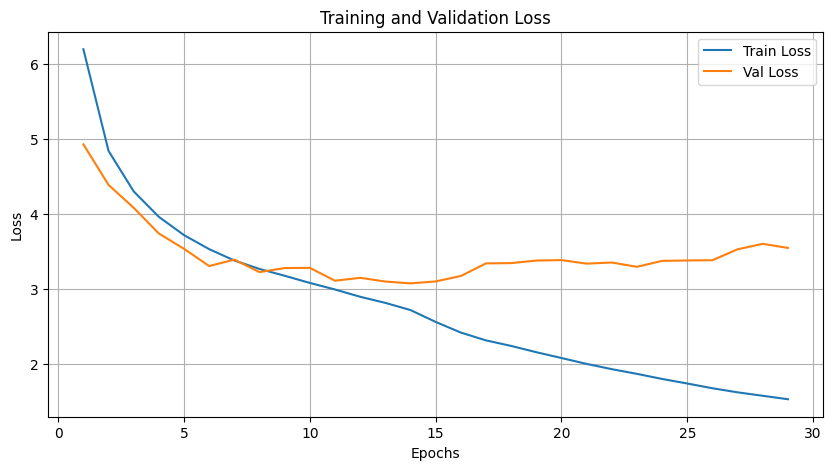

In [15]:
# Plotting Train/Validation losses
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses_history) + 1), train_losses_history, label='Train Loss')
plt.plot(range(1, len(val_losses_history) + 1), val_losses_history, label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

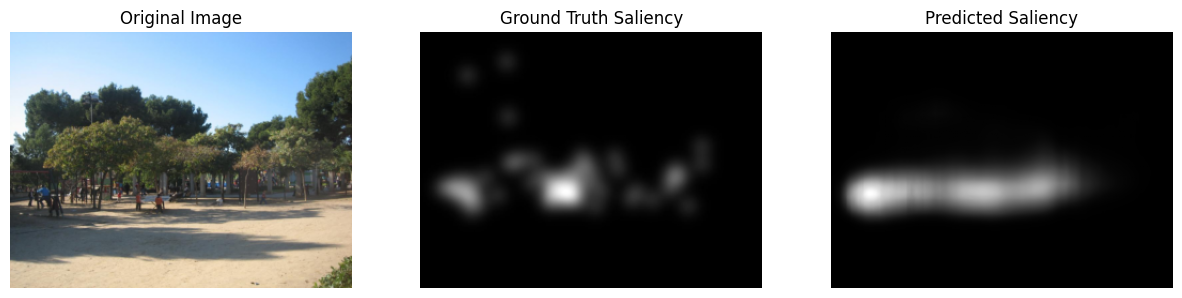

In [50]:
with torch.no_grad():
    img_idx = 1

    # first element of the last image batch
    sample_img = image_batch[img_idx].cpu()
    sample_gt = saliency_map_batch[img_idx].cpu()
    sample_pred = final_saliency_map[img_idx].cpu()

    # Unnormalize image for visualization (assuming ToTensor() was used)
    img_display = sample_img.permute(1, 2, 0).numpy()
    gt_display = sample_gt.squeeze().numpy()
    pred_display = sample_pred.squeeze().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_display)
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].imshow(gt_display, cmap='gray')
    axes[1].set_title('Ground Truth Saliency')
    axes[1].axis('off')

    axes[2].imshow(pred_display, cmap='gray')
    axes[2].set_title('Predicted Saliency')
    axes[2].axis('off')

    plt.show()

In [45]:
# Quantitative evaluation on the held-out MIT1003 test set (never seen during training)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

encoder.eval()
decoder3.eval()
decoder4.eval()
decoder5.eval()
final.eval()

total_test_loss = 0.0
total_kld, total_cc, total_sim = 0.0, 0.0, 0.0
n_batches = 0

with torch.no_grad():
    for image_batch, saliency_map_batch in test_dataloader:
        image_batch = image_batch.to(device)
        saliency_map_batch = saliency_map_batch.to(device)

        latent_features = encoder(image_batch)
        saliency_3 = decoder3(latent_features[0])
        saliency_4 = decoder4(latent_features[1])
        saliency_5 = decoder5(latent_features[2])
        fused_input = torch.cat((saliency_3, saliency_4, saliency_5), dim=1)
        final_saliency_map = final(fused_input)

        # Same total_loss used during training (deep supervision over final + 3 branches),
        # so this number is directly comparable to train_losses_history / val_losses_history
        loss = total_loss(final_saliency_map, saliency_3, saliency_4, saliency_5, saliency_map_batch)
        total_test_loss += loss.item()

        # cc_loss/sim_loss are expressed as (1 - metric), so we undo that here to report the actual metric
        total_kld += kld_loss(final_saliency_map, saliency_map_batch).item()
        total_cc += (1 - cc_loss(final_saliency_map, saliency_map_batch)).item()
        total_sim += (1 - sim_loss(final_saliency_map, saliency_map_batch)).item()
        n_batches += 1

avg_test_loss = total_test_loss / n_batches

print(f"MIT1003 Test Set - Total Loss: {avg_test_loss:.4f} (comparable to Train/Val Loss above)")
print(f"MIT1003 Test Set - KLD: {total_kld / n_batches:.4f} (lower is better)")
print(f"MIT1003 Test Set - CC:  {total_cc / n_batches:.4f} (higher is better)")
print(f"MIT1003 Test Set - SIM: {total_sim / n_batches:.4f} (higher is better)")

MIT1003 Test Set - Total Loss: 7.6305 (comparable to Train/Val Loss above)
MIT1003 Test Set - KLD: 0.9229 (lower is better)
MIT1003 Test Set - CC:  0.6044 (higher is better)
MIT1003 Test Set - SIM: 0.4809 (higher is better)


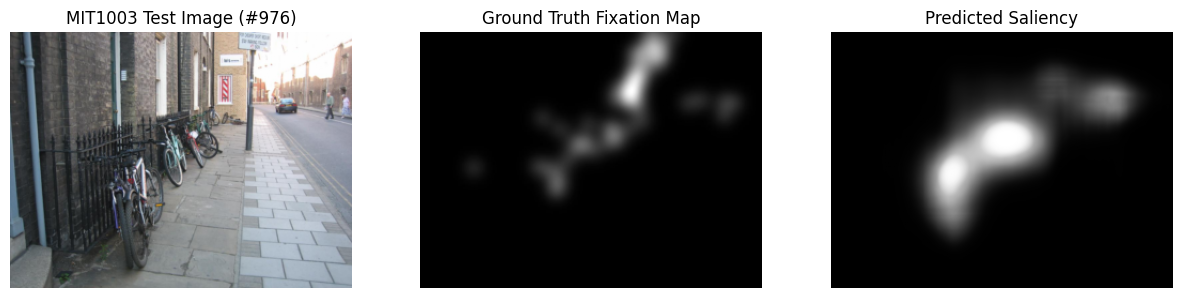

In [54]:
# Qualitative check on a random MIT1003 test sample (Original / Ground Truth / Predicted)
encoder.eval()
decoder3.eval()
decoder4.eval()
decoder5.eval()
final.eval()

with torch.no_grad():
    idx = random.randrange(len(test_dataset))
    sample_img, sample_gt = test_dataset[idx]

    input_tensor = sample_img.unsqueeze(0).to(device)

    latent = encoder(input_tensor)
    s3 = decoder3(latent[0])
    s4 = decoder4(latent[1])
    s5 = decoder5(latent[2])
    fused = torch.cat((s3, s4, s5), dim=1)
    prediction = final(fused)

    img_display = sample_img.permute(1, 2, 0).numpy()
    gt_display = sample_gt.squeeze().numpy()
    pred_display = prediction.squeeze().cpu().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_display)
    axes[0].set_title(f"MIT1003 Test Image (#{idx})")
    axes[0].axis('off')

    axes[1].imshow(gt_display, cmap='gray')
    axes[1].set_title('Ground Truth Fixation Map')
    axes[1].axis('off')

    axes[2].imshow(pred_display, cmap='gray')
    axes[2].set_title('Predicted Saliency')
    axes[2].axis('off')

    plt.show()